In [1]:
import time

import math

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
from sympy.tensor import tensor
%pprint # to print arrays on one line

Pretty printing has been turned OFF


In [2]:
torch.manual_seed(42)

In [3]:
names = open("C:\\dev\\tutorials\\LLM2\\gpt\\makemore\\names.txt", "r").read().splitlines()
names[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [4]:
#Global vars
input_size = 3 #number of letters that we pass to NN in one pass
dimension = 2 #dimension of a vector representing a letter

In [5]:
dic = sorted(set(ltr for name in names for ltr in name))
dic.append(".")

stoi = {s: i + 1 for i, s in enumerate(dic)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}

EMB = torch.rand([len(dic), dimension], requires_grad=True) #embeddings for all the letters in one matrix

for ch in ".ema":
  print(f"emb[{ch}]={ EMB[stoi[ch]] }")

emb[.]=tensor([0.8823, 0.9150], grad_fn=<SelectBackward0>)
emb[e]=tensor([0.9346, 0.5936], grad_fn=<SelectBackward0>)
emb[m]=tensor([0.3588, 0.1994], grad_fn=<SelectBackward0>)
emb[a]=tensor([0.3829, 0.9593], grad_fn=<SelectBackward0>)


In [6]:
#creating samples as a set of letter indices
def create_samples(input_size = 3) :
  index_samples = []
  index_answers = []
  for name in names:
    cur = "."*input_size + name + "."
    for i in range(0, len(cur)-input_size):
      index_samples.append(torch.tensor([stoi[ch] for ch in cur[i : i+input_size]]))
      index_answers.append(torch.tensor(stoi[cur[i+input_size]]))

  X = torch.stack(index_samples)
  Y = torch.stack(index_answers)
  return X, Y

X, Y = create_samples()
# print(f"{ len(index_samples)=}")
# print(f"{ index_samples[:5]=}")
# print(f"{[[itos[i] for i in smp.tolist()] for smp in index_samples[:5]]}")
# print(f"{index_answers[0]=}")
X.shape, Y.shape, EMB.shape

(torch.Size([228146, 3]), torch.Size([228146]), torch.Size([27, 2]))

In [21]:
#parametrized learning loop

def train(input_size = 3, dimension = 2, batch_size = 32, lr = 1.0, steps_count = 10000) :
  torch.manual_seed(42)
  dic_size = len(dic)
  EMB = torch.rand([dic_size, dimension], requires_grad=True) #embeddings for all the letters in one matrix
  X, Y = create_samples(input_size)
  perm = torch.randperm(X.shape[0])
  n = int(0.9 * len(perm))
  Xtr, Xval = X[perm[:n]], X[perm[n:]]
  Ytr, Yval = Y[perm[:n]], Y[perm[n:]]
  W = torch.rand([input_size * dimension, dic_size], requires_grad=True)
  B = torch.rand([dic_size], requires_grad=True)

  #learning loop
  t0 = time.perf_counter()
  times = []
  losses = []
  params_tables = [EMB, W, B]
  for i in range(steps_count):
    batch = torch.randint(0, Xtr.shape[0], (batch_size,)) #indices that we have chosen for the current batch
    X_emb = EMB[Xtr[batch]].view(-1, input_size*dimension)
    LOGITS = X_emb @ W + B
    loss = F.cross_entropy(LOGITS, Ytr[batch])

    for params_table in params_tables:
      params_table.grad = None

    loss.backward()

    losses.append(loss.item())
    times.append(time.perf_counter()-t0)
    if i % 1000 == 0:
      print(f"step = {i}, loss={loss.item(), math.exp(loss.item())}")

    with(torch.no_grad()):
      for params_table in params_tables:
        params_table -= lr * params_table.grad

  def forward(X):                      # X: [N, input_size] letter indices
    with torch.no_grad():
      return EMB[X].view(-1, input_size*dimension) @ W + B

  train_loss = F.cross_entropy(forward(Xtr), Ytr).item()
  val_loss = F.cross_entropy(forward(Xval), Yval).item()

  return {"times": times, "losses": losses, "forward": forward, "input_size": input_size, "val_loss": val_loss, "train_loss": train_loss}


results = {
  # "3x2 [32] 0.1 10_000": train(lr=0.1),
  "3x2 [32] 1.0 10_000": train(lr=1.0),
  "3x2 [250000] 1 1000": train(input_size=3, batch_size=250_000, dimension=2, lr=1.0, steps_count=1000),
  # "3x2 [32] 0.01 10_000": train(lr=0.01)
  # "3x3 [32] 0.1 10_000": train(dimension=3, lr=0.1),
  # "3x4 [32] 0.1 10_000": train(dimension=4, lr=0.1),
  # "3x6 [32] 0.1 10_000": train(dimension=6, lr=0.1),
  # "3x10 [32] 0.1 10_000": train(dimension=10, lr=0.1),
  "5x10 [32] 0.1 10_000": train(input_size=5, dimension=10, lr=0.1),
  # "10x10 [32] 0.1 30_000": train(input_size=10, dimension=10, lr=0.1, steps_count=30000),
}



step = 0, loss=(3.23315691947937, 25.359588915458215)
step = 1000, loss=(2.251539707183838, 9.50235542343753)
step = 2000, loss=(2.1461400985717773, 8.551785559997501)
step = 3000, loss=(2.1733667850494385, 8.787820994895059)
step = 4000, loss=(2.5751383304595947, 13.133133745269378)
step = 5000, loss=(2.6605985164642334, 14.30484822421387)
step = 6000, loss=(2.302518844604492, 9.999337538048225)
step = 7000, loss=(2.2979013919830322, 9.95327250412165)
step = 8000, loss=(2.7034239768981934, 14.930766904328104)
step = 9000, loss=(2.2959539890289307, 9.933908332885967)
step = 0, loss=(3.261183023452759, 26.080372591825007)
step = 0, loss=(4.069369792938232, 58.52007120637812)
step = 1000, loss=(2.3398678302764893, 10.379864568235712)
step = 2000, loss=(2.2943644523620605, 9.918130564338377)
step = 3000, loss=(2.314887523651123, 10.123784168423185)
step = 4000, loss=(2.1427900791168213, 8.523184845220294)
step = 5000, loss=(2.192960500717163, 8.961705014828325)
step = 6000, loss=(2.126974

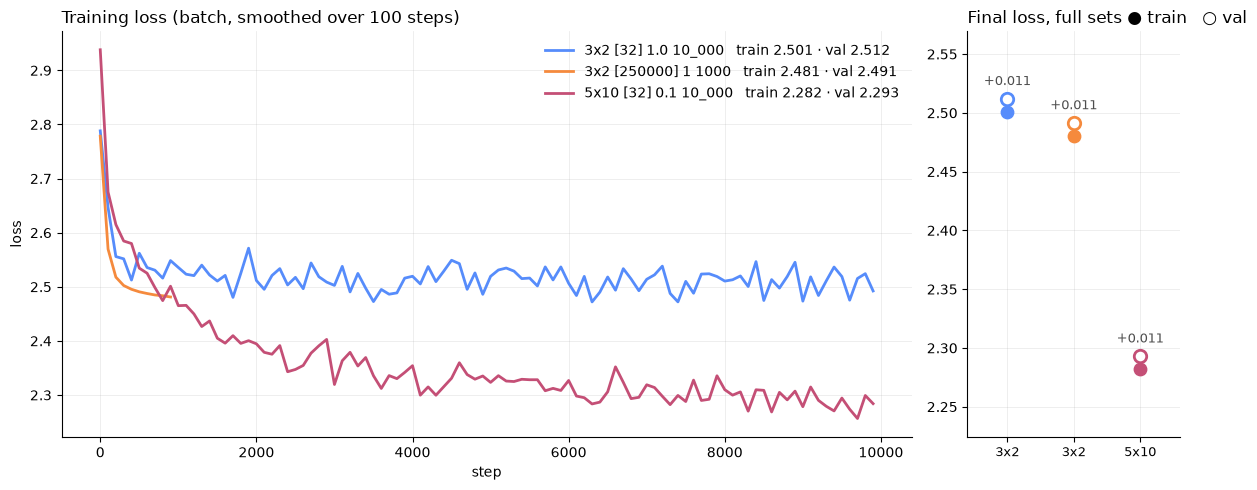

In [23]:
fig, (ax, ax_end) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [4, 1]})
for k, (name, r) in enumerate(results.items()):
  color = f"C{k}"
  tr, val = r["train_loss"], r["val_loss"]
  smooth = torch.tensor(r["losses"]).view(-1, 100).mean(1)
  ax.plot(range(0, len(r["losses"]), 100), smooth, color=color, lw=2,
          label=f"{name}   train {tr:.3f} · val {val:.3f}")
  ax_end.plot([k, k], [tr, val], color=color, lw=2, alpha=0.4)
  ax_end.scatter(k, tr, s=80, color=color, zorder=3)
  ax_end.scatter(k, val, s=80, facecolor="white", edgecolor=color, lw=2, zorder=3)
  ax_end.annotate(f"{val - tr:+.3f}", (k, max(tr, val)), xytext=(0, 10),
                  textcoords="offset points", ha="center", fontsize=9, color="0.3")

ax.set_title("Training loss (batch, smoothed over 100 steps)", loc="left")
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.legend(frameon=False)

ax_end.set_title("Final loss, full sets ● train   ○ val", loc="left")
ax_end.set_xticks(range(len(results)), [n.split()[0] for n in results], fontsize=9)
ax_end.set_xlim(-0.6, len(results) - 0.4)
ax_end.margins(y=0.25)

for a in (ax, ax_end):
  a.grid(alpha=0.3)
  a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

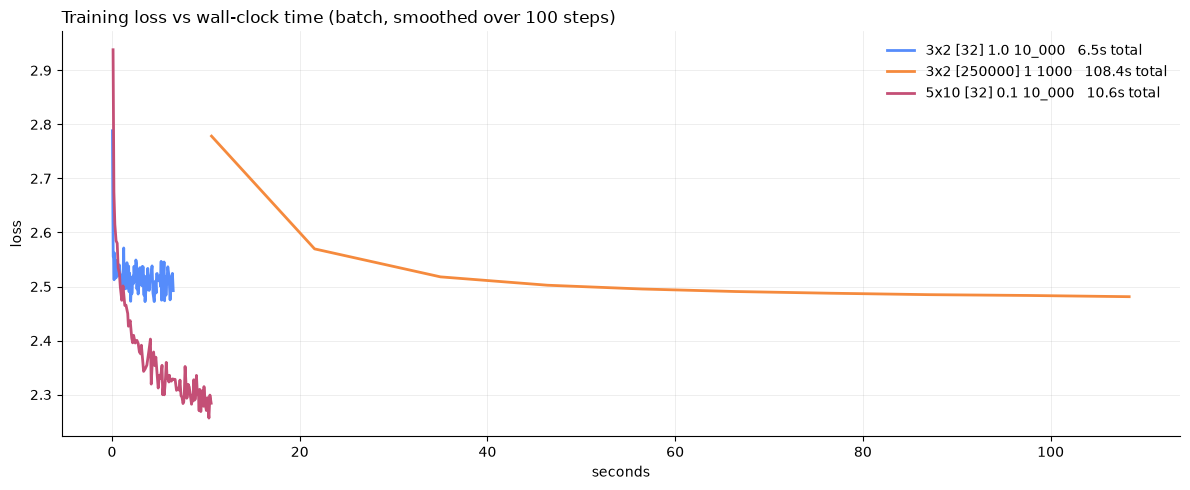

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, (name, r) in enumerate(results.items()):
  smooth = torch.tensor(r["losses"]).view(-1, 100).mean(1)
  t = torch.tensor(r["times"]).view(-1, 100)[:, -1]
  ax.plot(t, smooth, color=f"C{k}", lw=2, label=f"{name}   {r['times'][-1]:.1f}s total")

ax.set_title("Training loss vs wall-clock time (batch, smoothed over 100 steps)", loc="left")
ax.set_xlabel("seconds")
ax.set_ylabel("loss")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
def gen_name(forward, input_size) -> str:
  name = ""
  cur = "." * input_size
  while True:
    inp = torch.tensor([stoi[ch] for ch in cur])
    res = forward(inp)
    probs = res.softmax(dim = -1)
    ch = itos[torch.multinomial(probs, 1).item()]
    if ch == ".":
      break
    name += ch
    cur = cur[1:] + ch
  return name

trained_nn_best = results["5x10 [32] 0.1 10_000"]
trained_nn_default = results["3x2 [32] 1.0 10_000"]
generated_best = [gen_name(trained_nn_best["forward"], trained_nn_best["input_size"]) for names in range(10)]
generated_default = [gen_name(trained_nn_default["forward"], trained_nn_default["input_size"]) for names in range(10)]
generated_best, generated_default

(['sareeen', 'ahire', 'raille', 'ipalyna', 'handi', 'bommey', 'rixka', 'bukaisse', 'uusan', 'cancte'], ['rolrorhli', 'hynlinaolale', 'sei', 'cey', 'anl', 'jalre', 'caelalighiamon', 'betana', 'huza', 'rialua'])

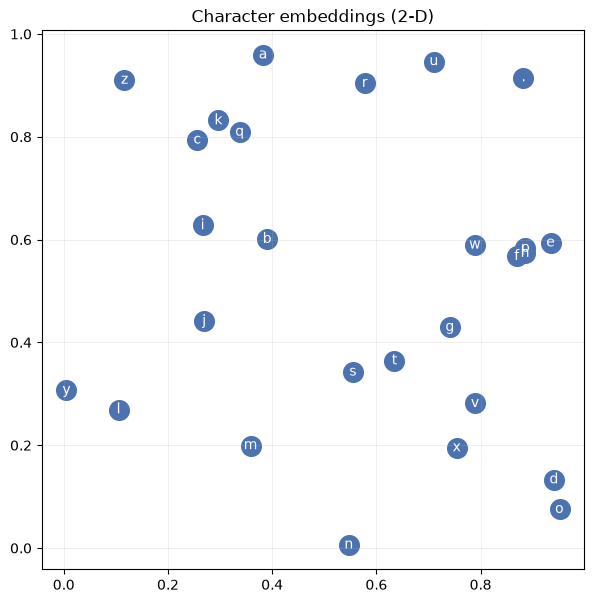

In [10]:
E = EMB.detach()   # leave autograd so matplotlib can read the values

plt.figure(figsize=(7, 7))
plt.scatter(E[:, 0], E[:, 1], s=200, color="#4C72B0")
for i in range(E.shape[0]):
  plt.text(E[i, 0], E[i, 1], itos[i], ha="center", va="center", color="white")
plt.grid(alpha=0.3)
plt.title("Character embeddings (2-D)")
plt.show()